In [3]:
import numpy as np

ModuleNotFoundError: No module named 'scipy'

In [4]:
! pip install scipy matplotlib

  Using cached scipy-1.15.2-cp313-cp313-win_amd64.whl.metadata (60 kB)
  Using cached matplotlib-3.10.1-cp313-cp313-win_amd64.whl.metadata (11 kB)
  Using cached contourpy-1.3.1-cp313-cp313-win_amd64.whl.metadata (5.4 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.57.0-cp313-cp313-win_amd64.whl.metadata (104 kB)
  Using cached kiwisolver-1.4.8-cp313-cp313-win_amd64.whl.metadata (6.3 kB)
  Using cached pillow-11.1.0-cp313-cp313-win_amd64.whl.metadata (9.3 kB)
  Using cached pyparsing-3.2.3-py3-none-any.whl.metadata (5.0 kB)
Using cached scipy-1.15.2-cp313-cp313-win_amd64.whl (41.0 MB)
Using cached matplotlib-3.10.1-cp313-cp313-win_amd64.whl (8.1 MB)
Using cached contourpy-1.3.1-cp313-cp313-win_amd64.whl (220 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
Using cached fonttools-4.57.0-cp313-cp313-win_amd64.whl (2.2 MB)
Using cached kiwisolver-1.4.8-cp313-cp313-win_amd64.whl (71 kB)
Using cached pillow-11.1.0-cp313-cp313-win_amd64.

Matplotlib is building the font cache; this may take a moment.


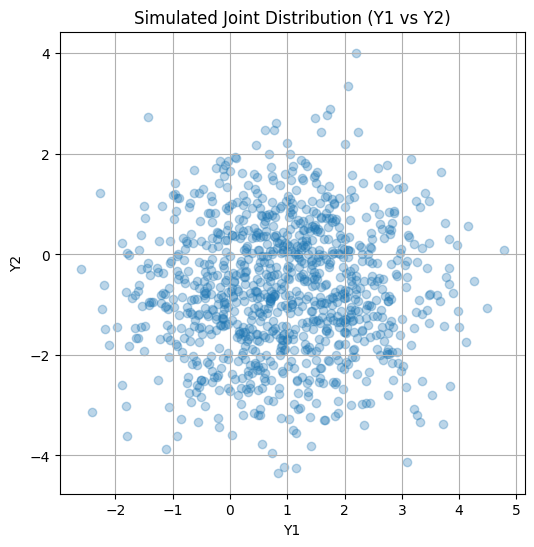

In [5]:
import numpy as np
from scipy.stats import norm
import matplotlib.pyplot as plt

# Set seed for reproducibility
np.random.seed(42)

# Number of samples
n = 100_000

# Step 1: Generate uniform covariates X1 and X2
X1 = np.random.uniform(0, 1, n)
X2 = np.random.uniform(0, 1, n)

# Step 2: Define functions for dependence and marginal location parameters
def theta_func(x1, x2):
    # Map to [-1, 1]
    return np.tanh(2 * x1 - x2)

def mu1_func(x1, x2):
    return 2 * x1 + np.sin(2 * np.pi * x2)

def mu2_func(x1, x2):
    return -1.5 * x2 + np.cos(2 * np.pi * x1)

# Step 3: Sample from FGM copula and transform marginals

# Sample independent U, V from Uniform(0, 1)
U = np.random.uniform(0, 1, n)
V_indep = np.random.uniform(0, 1, n)

# Compute theta values per observation
theta_vals = theta_func(X1, X2)

# Apply FGM copula transformation
V = V_indep + theta_vals * V_indep * (1 - V_indep) * (1 - 2 * U)

# Ensure values remain in [0, 1] (clipping to handle numerical issues)
V = np.clip(V, 1e-10, 1 - 1e-10)
U = np.clip(U, 1e-10, 1 - 1e-10)

# Step 4: Apply inverse CDF (normal) with varying means
mu1_vals = mu1_func(X1, X2)
mu2_vals = mu2_func(X1, X2)

# Standard deviation is 1, so we use loc=mu and scale=1
Y1 = norm.ppf(U, loc=mu1_vals, scale=1)
Y2 = norm.ppf(V, loc=mu2_vals, scale=1)

# ✅ Done! Y1 and Y2 are now sampled from your desired joint distribution.

# Optional: plot a sample of the results
plt.figure(figsize=(6, 6))
plt.scatter(Y1[:1000], Y2[:1000], alpha=0.3)
plt.title("Simulated Joint Distribution (Y1 vs Y2)")
plt.xlabel("Y1")
plt.ylabel("Y2")
plt.grid(True)
plt.show()


In [7]:
! pip install --upgrade git+https://github.com/supsi-dacd-isaac/mbtr.git

  Cloning https://github.com/supsi-dacd-isaac/mbtr.git to c:\users\antho\appdata\local\temp\pip-req-build-0v2u2jxf
  Resolved https://github.com/supsi-dacd-isaac/mbtr.git to commit 37eb7233b277db4a6847b1af6a33b2b25f6e4799
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
  Using cached pandas-2.2.3-cp313-cp313-win_amd64.whl.metadata (19 kB)
  Using cached pytz-2025.2-py2.py3-none-any.whl.metadata (22 kB)
   ---------------------------------------- 0.0/1.5 MB ? eta -:--:--
   --------------------- ------------------ 0.8/1.5 MB 6.2 MB/s eta 0:00:01
   ---------------------------------------- 1.5/1.5 MB 5.6 MB/s eta 0:00:00
   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   -------------------

  Running command git clone --filter=blob:none --quiet https://github.com/supsi-dacd-isaac/mbtr.git 'C:\Users\antho\AppData\Local\Temp\pip-req-build-0v2u2jxf'
  You can safely remove it manually.
  You can safely remove it manually.
